# Analysis
Statistical comparison of the systems trained in `Experiments.ipynb`. This notebook only reads the scores the experiments
saved to `results/<experiment>/cv_scores.csv` (and `test_scores.csv`), so it needs no retraining and no data loading.

In [23]:
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd

import part1  # to use code from tutorial

# must match Experiments.ipynb
results_folder = Path("./results")
my_seeds = [0, 1, 2]

def load_scores(kind="cv"):
    """All saved scores of one kind ("cv" or "test"), one row per (model, seed, fold)."""
    frames = [pd.read_csv(path).assign(model=path.parent.name) for path in sorted(results_folder.glob(f"*/{kind}_scores.csv"))]
    return pd.concat(frames, ignore_index=True)[["model", "seed", "fold", "accuracy", "f1"]]

In [24]:
# test-set scores (mean and std over the fold models), for reference
load_scores("test").groupby("model")[["accuracy", "f1"]].agg(["mean", "std"]).round(4)

accuracy              f1        
                              mean     std    mean     std
model                                                     
logistic_bow-lemmas         0.6845  0.0024  0.6309  0.0059
logistic_embeddings         0.6559  0.0005  0.5911  0.0005
logistic_indicator-lemmas   0.6890  0.0007  0.6443  0.0009
mlp2_bow-lemmas             0.6998  0.0013  0.6629  0.0045
mlp2_embeddings             0.6831  0.0015  0.6468  0.0058
mlp2_indicator-lemmas       0.6986  0.0014  0.6654  0.0040
mlp_bow-lemmas              0.7005  0.0010  0.6627  0.0048
mlp_embeddings              0.6879  0.0012  0.6521  0.0035
mlp_indicator-lemmas        0.7008  0.0014  0.6648  0.0036

## ROPE Analysis: Picking Amongst Design Choices
Following the tutorial (*Picking Amongst Design Choices*), we compare systems with the Bayesian correlated t-test of
[Benavoli et al. 2017](https://jmlr.org/papers/volume18/16-305/16-305.pdf), via `part1.analysis.BenavoliCorrelatedT`.
It gives a posterior over the mean difference in performance (B − A) across the cross-validation folds, and the probability
that this difference lies left of, inside, or right of a region of practical equivalence (ROPE).

* **Metric:** macro F1 on the validation folds (the classes are imbalanced, so accuracy is also reported for comparison).
* **Data:** the per-fold scores saved in `results/<experiment>/cv_scores.csv`, so this section needs no retraining.
* **Runs:** each seed is a separate run of 5-fold cross-validation (`runs=len(my_seeds)`), so the test corrects for the
  correlation between folds of the same run. Folds are paired: for a given seed and fold, all systems were trained and
  validated on the same rows.
* **ROPE:** ±0.01 (one point of F1 or accuracy); the tutorial uses ±0.005.

In [25]:
# settings for the analysis
ROPE_SIZE = 0.01         # differences smaller than this (in F1 / accuracy) count as practically equivalent
DECISION_PROB = 0.95     # a region (A wins / tie / B wins) needs at least this posterior probability to call a decision

cv_scores = load_scores("cv")  # one row per (model, seed, fold), with accuracy and macro F1
cv_scores.groupby("model")[["accuracy", "f1"]].agg(["mean", "std"]).round(4)

accuracy              f1        
                              mean     std    mean     std
model                                                     
logistic_bow-lemmas         0.6851  0.0030  0.6323  0.0065
logistic_embeddings         0.6569  0.0018  0.5930  0.0019
logistic_indicator-lemmas   0.6903  0.0015  0.6466  0.0015
mlp2_bow-lemmas             0.7009  0.0018  0.6643  0.0050
mlp2_embeddings             0.6848  0.0018  0.6491  0.0048
mlp2_indicator-lemmas       0.7008  0.0016  0.6682  0.0046
mlp_bow-lemmas              0.7021  0.0015  0.6649  0.0050
mlp_embeddings              0.6891  0.0019  0.6538  0.0040
mlp_indicator-lemmas        0.7032  0.0021  0.6678  0.0037

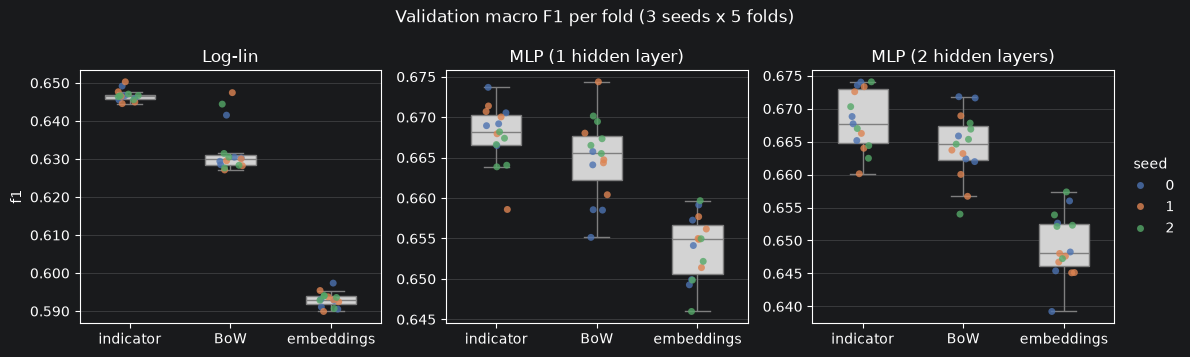

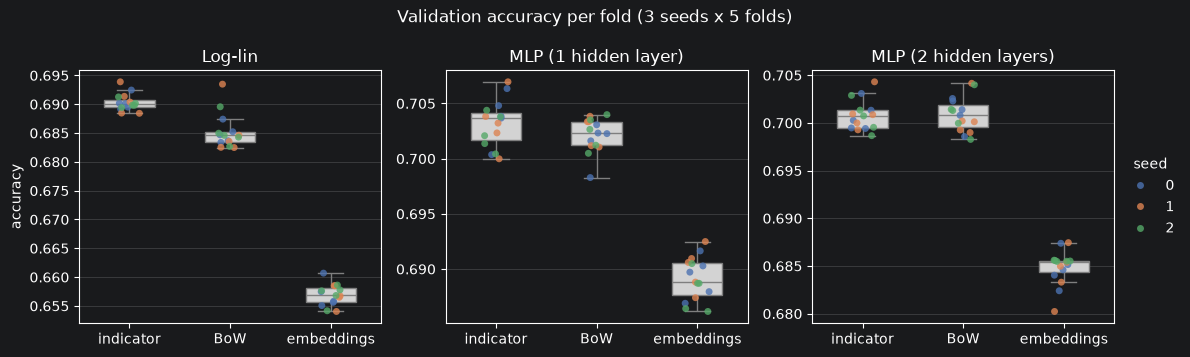

In [26]:
# fold scores per system, as in the tutorial, but split into one panel per architecture so each panel shows only
# the three representations (each panel has its own y-axis range; mind the scale when comparing across panels)
import matplotlib.pyplot as plt
import seaborn as sns

FAMILIES = {"logistic": "Log-lin", "mlp": "MLP (1 hidden layer)", "mlp2": "MLP (2 hidden layers)"}
REPRESENTATIONS = {"indicator-lemmas": "indicator", "bow-lemmas": "BoW", "embeddings": "embeddings"}

def plot_fold_scores(scores, metric="f1"):
    """Box plot plus one dot per (seed, fold) score, one panel per architecture."""
    parts = scores["model"].str.split("_", n=1, expand=True)  # e.g. "mlp2_bow-lemmas" -> "mlp2", "bow-lemmas"
    data = scores.assign(family=parts[0], representation=parts[1].map(REPRESENTATIONS))
    families = [f for f in FAMILIES if f in set(data["family"])]
    fig, axes = plt.subplots(1, len(families), figsize=(4 * len(families), 3.6), squeeze=False)
    for ax, fam in zip(axes[0], families):
        panel = data[data["family"] == fam]
        order = [r for r in REPRESENTATIONS.values() if r in set(panel["representation"])]
        sns.boxplot(data=panel, x="representation", y=metric, order=order, color="lightgray",
                    showfliers=False, width=0.5, ax=ax)
        sns.stripplot(data=panel, x="representation", y=metric, hue="seed", order=order, palette="deep",
                      jitter=0.12, size=5, alpha=0.8, ax=ax, legend=ax is axes[0][-1])
        ax.set(title=FAMILIES[fam], xlabel="", ylabel=metric if ax is axes[0][0] else "")
        ax.grid(axis="y", alpha=0.3)
        ax.yaxis.set_major_formatter("{x:.3f}")
    axes[0][-1].legend(title="seed", loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
    fig.suptitle(f"Validation {'macro F1' if metric == 'f1' else metric} per fold (3 seeds x 5 folds)")
    fig.tight_layout()
    plt.show()

plot_fold_scores(cv_scores, metric="f1")
plot_fold_scores(cv_scores, metric="accuracy")

In [27]:
# First, a little helper, to gather all measurements across runs and folds, in the same (seed, fold) order for every
# system, so the scores of two systems are paired
def get_all_measurements_for(scores, sys_name, metric="f1"):
    table = scores[scores["model"] == sys_name].pivot(index="seed", columns="fold", values=metric)
    table = table.loc[my_seeds].sort_index(axis=1)  # rows: runs (seeds), columns: folds
    assert not table.isna().any().any(), f"missing folds for {sys_name}"
    return table.to_numpy()

# this will have shape [num_runs, num_folds]
get_all_measurements_for(cv_scores, "logistic_indicator-lemmas")

array([[0.64916772, 0.64553361, 0.64625763, 0.64665079, 0.64589397],
       [0.64454971, 0.64645431, 0.65028519, 0.64766638, 0.64496026],
       [0.64661802, 0.64668873, 0.64705819, 0.64556719, 0.64638069]])

A=logistic_indicator-lemmas B=mlp_indicator-lemmas: P(A wins)=0.0000 P(Tie)=0.0000 P(B wins)=1.0000 Effect Size=11.88


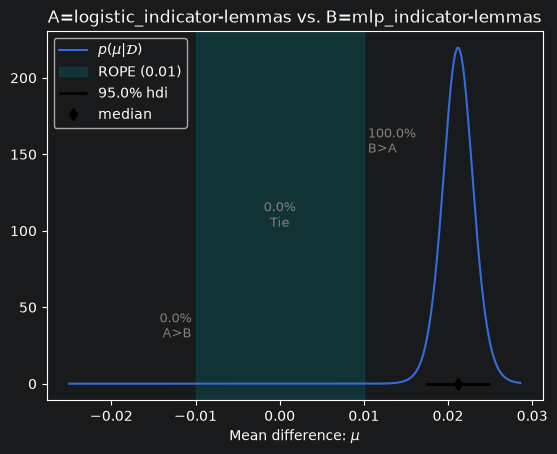

In [28]:
def compare(sys_a, sys_b, metric="f1", scores=cv_scores):
    """Posterior over the mean difference (B - A) between two systems, from their paired fold scores."""
    return part1.analysis.BenavoliCorrelatedT(
        get_all_measurements_for(scores, sys_a, metric).flatten(),  # shape [num_runs * num_folds]
        get_all_measurements_for(scores, sys_b, metric).flatten(),  # shape [num_runs * num_folds]
        runs=len(my_seeds),
        names=[sys_a, sys_b],
    )

# example, as in the tutorial: log-lin vs MLP with the token indicator
posterior = compare("logistic_indicator-lemmas", "mlp_indicator-lemmas")
p_a, p_tie, p_b = posterior.probs(ROPE_SIZE)
print(f"A=logistic_indicator-lemmas B=mlp_indicator-lemmas: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} "
      f"P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")
_ = posterior.plot(ROPE_SIZE)  # rope_factor only zooms the plot in or out, it doesn't change the ROPE

The plot shows the posterior over the mean difference (B − A) and the ROPE (shaded). The areas left of, inside and right
of the ROPE are the probabilities that A is better, that the two are practically equivalent, and that B is better.

In [29]:
def compare_all_pairs(scores=cv_scores, metric="f1", rope_size=ROPE_SIZE, decision_prob=DECISION_PROB):
    """Compares every pair of systems; returns one row per pair with the posterior mean difference (B - A),
    the ROPE probabilities and a decision (the region with at least `decision_prob`, or "undecided")."""
    rows = []
    for sys_a, sys_b in combinations(sorted(scores["model"].unique()), 2):
        posterior = compare(sys_a, sys_b, metric, scores)
        p_a, p_tie, p_b = posterior.probs(rope_size)
        regions = {"A better": p_a, "tie": p_tie, "B better": p_b}
        best = max(regions, key=regions.get)
        rows.append({"A": sys_a, "B": sys_b, "mean diff (B-A)": posterior.mean_diff,
                     "P(A wins)": p_a, "P(tie)": p_tie, "P(B wins)": p_b,
                     "effect size": posterior.effect_size,
                     "decision": best if regions[best] >= decision_prob else "undecided"})
    return pd.DataFrame(rows)

pairs_f1 = compare_all_pairs(metric="f1")
pairs_f1.to_csv(results_folder / "rope_pairs_f1.csv", index=False)
pairs_f1.round(4)

,A,B,mean diff (B-A),P(A wins),P(tie),P(B wins),effect size,decision
0,logistic_bow-lemmas,logistic_embeddings,-0.0394,1.0000,0.0000,0.0000,-9.6583,A better
1,logistic_bow-lemmas,logistic_indicator-lemmas,0.0143,0.0000,0.1106,0.8894,4.2390,undecided
2,logistic_bow-lemmas,mlp2_bow-lemmas,0.0320,0.0000,0.0000,1.0000,7.8397,B better
3,logistic_bow-lemmas,mlp2_embeddings,0.0168,0.0000,0.0515,0.9485,4.3022,undecided
4,logistic_bow-lemmas,mlp2_indicator-lemmas,0.0359,0.0000,0.0000,1.0000,10.1732,B better
5,logistic_bow-lemmas,mlp_bow-lemmas,0.0325,0.0000,0.0000,1.0000,7.8806,B better
6,logistic_bow-lemmas,mlp_embeddings,0.0215,0.0000,0.0173,0.9826,4.3705,B better
7,logistic_bow-lemmas,mlp_indicator-lemmas,0.0355,0.0000,0.0000,1.0000,9.4817,B better
8,logistic_embeddings,logistic_indicator-lemmas,0.0537,0.0000,0.0000,1.0000,64.1766,B better
9,logistic_embeddings,mlp2_bow-lemmas,0.0714,0.0000,0.0000,1.0000,23.0790,B better


In [30]:
# the same comparison on accuracy
pairs_acc = compare_all_pairs(metric="accuracy")
pairs_acc.to_csv(results_folder / "rope_pairs_accuracy.csv", index=False)
pairs_acc.round(4)

,A,B,mean diff (B-A),P(A wins),P(tie),P(B wins),effect size,decision
0,logistic_bow-lemmas,logistic_embeddings,-0.0282,1.0000,0.0000,0.0000,-14.4895,A better
1,logistic_bow-lemmas,logistic_indicator-lemmas,0.0051,0.0000,0.9982,0.0018,3.7035,tie
2,logistic_bow-lemmas,mlp2_bow-lemmas,0.0157,0.0000,0.0015,0.9985,9.7754,B better
3,logistic_bow-lemmas,mlp2_embeddings,-0.0003,0.0001,0.9998,0.0001,-0.1565,tie
4,logistic_bow-lemmas,mlp2_indicator-lemmas,0.0157,0.0000,0.0005,0.9995,11.3354,B better
5,logistic_bow-lemmas,mlp_bow-lemmas,0.0170,0.0000,0.0013,0.9987,8.8836,B better
6,logistic_bow-lemmas,mlp_embeddings,0.0040,0.0000,0.9969,0.0031,2.1527,tie
7,logistic_bow-lemmas,mlp_indicator-lemmas,0.0180,0.0000,0.0001,0.9999,11.5423,B better
8,logistic_embeddings,logistic_indicator-lemmas,0.0334,0.0000,0.0000,1.0000,46.3803,B better
9,logistic_embeddings,mlp2_bow-lemmas,0.0440,0.0000,0.0000,1.0000,44.1660,B better


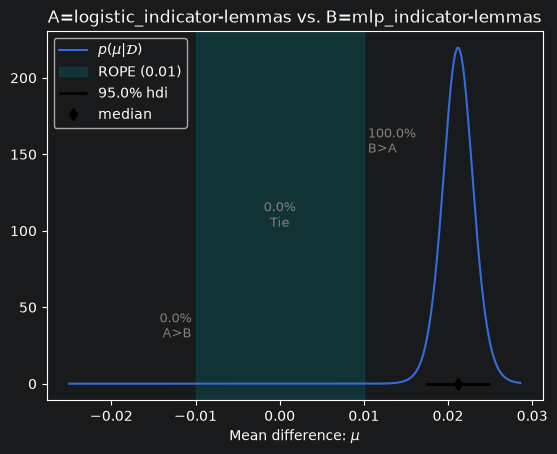

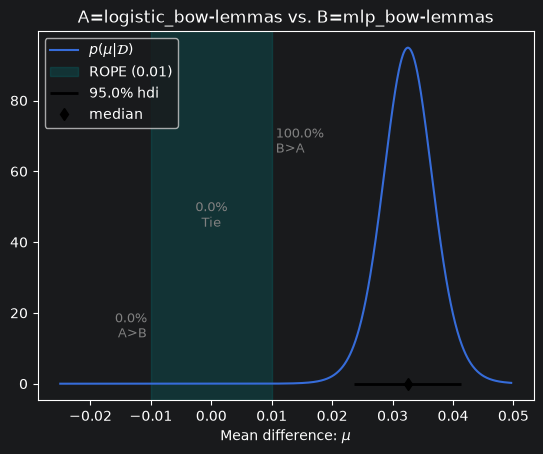

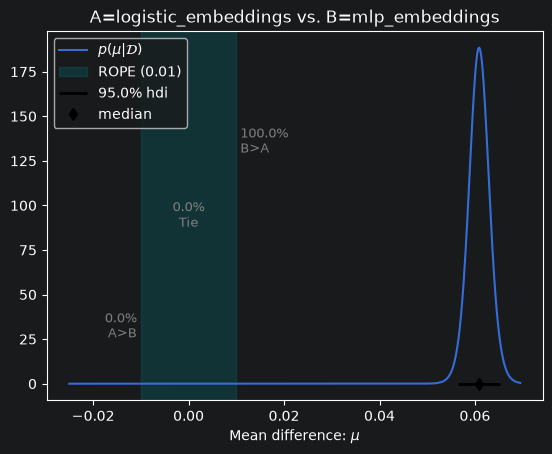

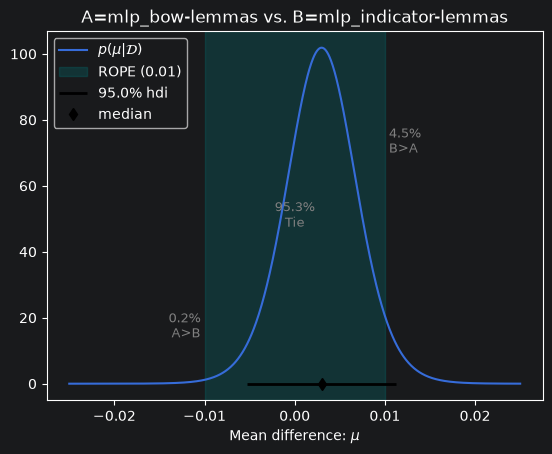

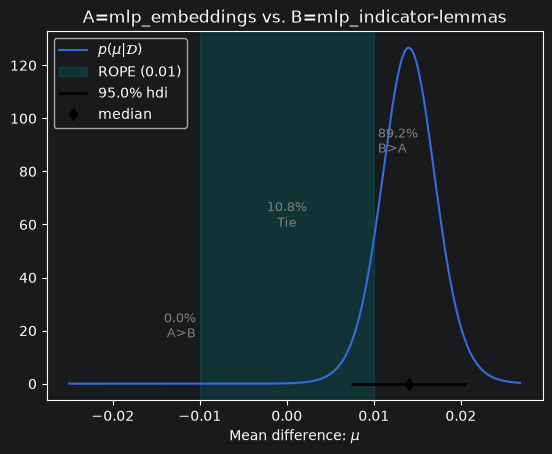

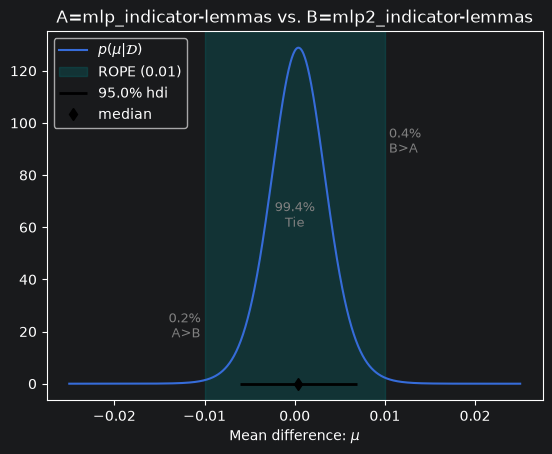

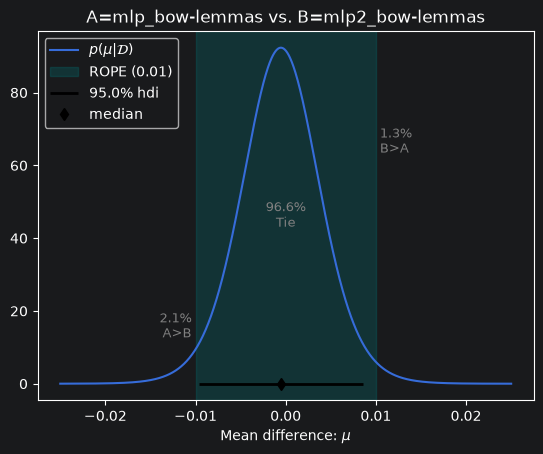

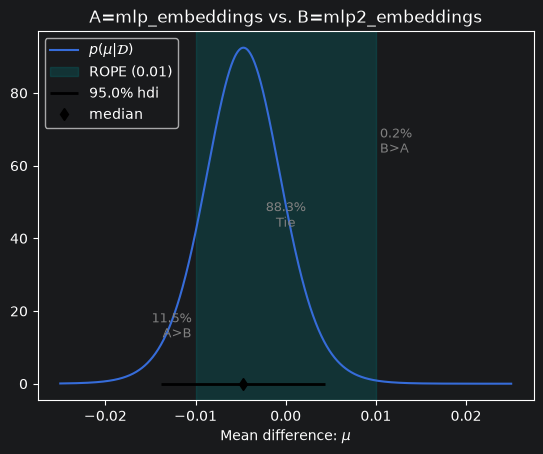

In [31]:
# posterior plots for the design choices we care most about (macro F1)
key_pairs = [
    # does the MLP improve on log-lin, for each representation?
    ("logistic_indicator-lemmas", "mlp_indicator-lemmas"),
    ("logistic_bow-lemmas", "mlp_bow-lemmas"),
    ("logistic_embeddings", "mlp_embeddings"),
    # which representation is best for the MLP?
    ("mlp_bow-lemmas", "mlp_indicator-lemmas"),
    ("mlp_embeddings", "mlp_indicator-lemmas"),
    # does a second hidden layer help?
    ("mlp_indicator-lemmas", "mlp2_indicator-lemmas"),
    ("mlp_bow-lemmas", "mlp2_bow-lemmas"),
    ("mlp_embeddings", "mlp2_embeddings"),
]
available = set(cv_scores["model"])
for sys_a, sys_b in key_pairs:
    if {sys_a, sys_b} <= available:
        _ = compare(sys_a, sys_b).plot(ROPE_SIZE)